# Gaussian experiment, from formulas to code

This notebook follows the six stages: compare DFM (MLP) and DFM (Gaussian + MLP),
freeze DFM (Gaussian + MLP), train CDG-ML (Guo et al., 2026; no refinements)
and Refined CDG-ML (all five refinements), then generate conditional returns and compare
five sources: the conditional ground truth, DFM rejection sampling, CDG-ML, Refined
CDG-ML, and no guidance, the last three with an exact final sampling step.
All five sources are saved with their samples and CSV files. The conditional figures
and tables show DFM rejection and Refined CDG-ML against the exact law; a final table
compares CDG-ML and Refined CDG-ML with DFM rejection.
The method and its assumptions are documented in [METHODS.md](METHODS.md);
section 1 below specifies the Chen population used in this execution.

Use $R$ for clean population returns, $s$ for forward OU noising time,
$t$ for elapsed generation time, and $\tau=T-t_0$. The ambient generated state is
$X_t$ and the reduced conditioning state is $Y_t=G_tX_t$.

**Sources.** The DFM's forward process, score network form, denoising score matching
and sampler, and the synthetic Gaussian factor population, follow Chen et al. (2025);
section 2 changes the time sampling and loss weighting. The Gaussian + MLP network is a
project adaptation. The terminal-event probability $H$, its Doob guidance, CDG-ML and
the guidance scale follow Guo et al. (2026).

## Configuration

The notebook defaults to `MODE="standard"`; set `MODE="smoke"` for a shorter
execution. Both modes compare the two DFM networks on the same draws and condition
DFM (Gaussian + MLP) at the 5% and 1% event levels. The effective configuration is
displayed by the code below. Both modes draw from the Chen et al. (2025) Gaussian
factor generator with fixed population seed 912.

| Setting | Notebook smoke | Notebook standard (default) |
| --- | ---: | ---: |
| Assets / factors | 12 / 8 | 500 / 8 |
| DFM train / validation / evaluation observations | 2,048 / 512 / 512 | 2,500 / 750 / 3,000 |
| DFM epochs / hidden widths | 15 / (32, 32) | 1,000 / (64, 64) |
| Integration steps | 100 | 400 |
| H train / validation / test trajectories | 2,048 / 1,024 / 1,024 | 40,000 / 2,000 / 2,000 |
| H epochs / hidden widths (validation every 157 optimizer steps) | 10 / (64, 64) | 50 / (64, 64) |
| Guided and ground-truth samples per source | 512 | 3,000 |
| Accepted samples per DFM rejection stream | 128 | 1,000 |
| Proposal cap per DFM rejection stream (5% / 1%) | 10,240 / 51,200 | 80,000 / 400,000 |


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from dataclasses import asdict, replace
import sys
import time

import numpy as np
import pandas as pd
from IPython.display import display, Markdown

ROOT = Path.cwd()
if not (ROOT / "DFM.py").exists():
    raise RuntimeError("Run this notebook with the repository as working directory")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

from reference import FrozenDFMReference
from sampling import generate_samples

In [2]:
from synthetic_benchmark.configuration import Config
from synthetic_benchmark.reporting import DFM_LABELS

In [3]:
import os
# Set to a saved run to keep its DFMs fixed; None trains new DFMs.
FROZEN_DFM_RUN = os.environ.get("SYNTHETIC_FROZEN_DFM_RUN")
MODE = "standard"  # smoke reduces dimensions and both DFM and H training budgets.
CONFIG_OVERRIDES = {
    # Chen et al. (2025) Gaussian factor population, fixed population seed 912 (section 1).
    "d": 12 if MODE == "smoke" else 500,
    "k": 8,
    "n_train": 2_048 if MODE == "smoke" else 2_500,
    "n_val": 512 if MODE == "smoke" else 750,
    # Selected using observed validation returns; the objective is explained below.
    "dfm_initialization": "pca",
    "dfm_time_sampling": "log_balanced",
    "dfm_loading_lr_scale": 0.1,
    "dfm_loading_warmup_epochs": 100,
    "lr": 1e-3,
    "torch_threads": 4,
    # "seeds": (42,),
    # "n_eval": 3_000, "dfm_epochs": 1_000, "steps": 400,
    # "T": 8.0, "t0": 0.005, "width": 64,
    # "batch": 256, "device": "cpu",
}
CONFIG = replace(Config.preset(MODE), **CONFIG_OVERRIDES)
# Both DFMs are trained on the same draws; guidance runs on DFM (Gaussian + MLP).
DFM_NETWORKS = ("mlp", "gaussian_mlp")
OUTPUT = ROOT / "artifacts" / "synthetic_unconditional_benchmark" / (
    MODE + "_" + datetime.now(timezone.utc).strftime("%Y%m%dT%H%M%S%fZ")
)
display(pd.Series(asdict(CONFIG), name="Effective DFM configuration").to_frame())
print(f"DFM training: {CONFIG.dfm_epochs:,} epochs per seed, for "
      + " and ".join(DFM_LABELS[network] for network in DFM_NETWORKS))
print("Artifacts:", OUTPUT)

,Effective DFM configuration
mode,standard
d,500
k,8
seeds,"(42,)"
cases,"(gaussian,)"
n_train,2500
n_val,750
n_eval,3000
dfm_epochs,1000
steps,400


DFM training: 1,000 epochs per seed, for DFM (MLP) and DFM (Gaussian + MLP)
Artifacts: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T181844904153Z


## 1. Construct the synthetic population

We use the Gaussian factor generator of Chen et al. (2025). Because the population is
Gaussian, its law and its law given a portfolio event are known exactly, so both the
fitted DFM and the conditioning procedure can be checked against them.

The standard experiment keeps $d=500,k=8$, 2,500 training observations and 750
validation observations. Smoke mode uses $d=12,k=8$ with reduced training budgets.
The population is drawn once with this project's fixed population seed 912,
independently of the observation, model, and evaluation seeds.

For the original factor coordinates, draw
$$
\mu_{F,j}\overset{\mathrm{iid}}\sim\operatorname{Unif}(0,0.1),\qquad
\sigma_{F,j}=1.5\mu_{F,j},\qquad
F\sim\mathcal N\!\left(\mu_F,\operatorname{diag}(\sigma_F^2)\right),
$$
$$
\beta_{ij}\overset{\mathrm{iid}}\sim\mathcal N(0,1),\qquad
\sigma_{\varepsilon,i}\overset{\mathrm{iid}}\sim\operatorname{Unif}(0,0.4),\qquad
\varepsilon\sim\mathcal N\!\left(0,\operatorname{diag}(\sigma_\varepsilon^2)\right),
$$
$$
F\perp\varepsilon,\qquad R=\beta F+\varepsilon.
$$
The draws of $\mu_F$, $\beta$, and $\sigma_\varepsilon$ are independent. These are raw
synthetic returns; no standardization or U-Net preprocessing is applied.

The code expresses exactly the same population in orthonormal coordinates using
$\beta=BA$, with $B^\top B=I_k$ and upper-triangular $A$ chosen to have a nonnegative
diagonal. Thus
$$
\widetilde F=AF\sim\mathcal N(m,S),\qquad
m=A\mu_F,\qquad
S=A\operatorname{diag}\!\left((1.5\mu_F)^2\right)A^\top,\qquad
D_i=\sigma_{\varepsilon,i}^2,
$$
$$
R=B\widetilde F+\varepsilon,\qquad
\mu=Bm=\beta\mu_F,\qquad
\Sigma=BSB^\top+\operatorname{diag}(D).
$$
In these QR coordinates, $S$ is generally a full matrix. All these population
parameters stay fixed across the independent training, validation and evaluation
draws.

The equal-weight portfolio and population event are
$$
w=\frac{\mathbf1}{d},\quad P=w^\top R\sim\mathcal N(a,v),\quad
 a=w^\top\mu,\quad v=w^\top\Sigma w,\quad
 C_q=a+\sqrt v\,\Phi^{-1}(q),\quad q\in\{0.05,0.01\}.
$$

The DFM sees returns only and learns its own $V$. The population generator follows
Chen's Gaussian specification, but the MLP architectures, training refinements and
conditioning experiment are our choices; the paper's U-Net experiments are not
replicated. Population dimensions and seed are saved with the checkpoints.


In [4]:
from synthetic_benchmark.unconditional import population_for_config

population = population_for_config(CONFIG)

## 2. Train and sample the unconditional DFM

We compare **DFM (MLP)** and **DFM (Gaussian + MLP)** on the same return draws.
Both use two training refinements to improve the unguided DFM's approximation of the
return distribution, particularly its covariance structure:

1. **Observation-based initialization and staged loading updates.** The loading matrix determines which directions of joint return variation the factor network sees. Starting from random directions makes the network learn this representation at the same time as it learns the score. We instead initialize the loadings with the principal components of the training returns and initialize the idiosyncratic variances from the remaining variation, as in the principal-components factor estimate of Bai (2003). We first hold the loadings fixed so the other parameters can adapt to these coordinates, then update them at a smaller learning rate.

2. **Log-spaced noising times and noise-variance-weighted score matching.** Uniform time sampling devotes few training examples to the small noising times that correspond to the final stages of generation, where the model must recover the detailed return distribution. Sampling times on a logarithmic scale gives these small times more coverage. At the same time, the denoising target grows as the noise level decreases; weighting the squared error by the noise variance counteracts this growth. The noise-variance weight follows Song et al. (2021) and Ho et al. (2020), and log-spaced noise levels appear in Song et al. (2019) and Karras et al. (2022). Both replace the uniform time weighting of Chen et al. (2025).

The notebook combines refinements (1) and (2) for both networks; their effective
configuration is displayed above.

For clean returns $R$, the forward OU corruption of Chen et al. (2025) is

$$
R_s=\alpha_s R+\sqrt{h_s}\,\xi,\qquad
\alpha_s=e^{-s/2},\quad h_s=1-e^{-s},\quad \xi\sim N(0,I_d).
$$

The learned score in [`FactorScoreNetwork.forward`](NeuralNets.py) is the
factor-aware score network of Chen et al. (2025):

$$
s_\theta(r,s)=\alpha_s D_s Vg_\zeta(V^\top D_s r,s)-D_sr,\qquad
D_s=\operatorname{diag}(h_s+\alpha_s^2 c_i)^{-1}.
$$

Here $V\in\mathbb R^{d\times k}$, $c_i=2\operatorname{sigmoid}(c_{\rm raw,i})$,
and the two-hidden-layer ReLU MLP $g_\zeta$ are learned jointly.
The fitted $V,c$ need not equal the population $B,D$. Chen et al. analyze this
form but use a 2D U-Net with approximately one billion parameters in their experiments;
here the theoretical form is implemented directly as **DFM (MLP)**.

**DFM (Gaussian + MLP)** keeps this outer score form and replaces only the inner map by
an exact Gaussian factor posterior mean plus an MLP correction. With
$M_s=V^\top D_sV$, $z=V^\top D_sr$, and a trainable factor prior $f\sim N(m_f,S_f)$,
$$
g(z,s)=m_f+(I_k+\alpha_s^2S_fM_s)^{-1}S_f\alpha_s(z-\alpha_sM_sm_f)
+g_\zeta(z,s).
$$
The Gaussian part supplies the affine
posterior mean, and the MLP learns departures from it. This replaces the paper's
empirical architecture and is favored by the Gaussian population, so it says nothing
about heavy tails. The two networks have 9,820 and 9,892 parameters in the standard
configuration.


In [5]:
from synthetic_benchmark.unconditional import (
    initialize_unconditional_run, prepare_unconditional_case, dfm_folder_name,
    fit_and_save_dfm, evaluate_unconditional_samples,
    save_unconditional_case, save_unconditional_summary,
)

### Unconditional sampling

After fitting, [`generate_samples`](sampling.py) approximates the reverse-time SDE
of Chen et al. (2025),

$$
dX_t=\left[\tfrac12X_t+s_\theta(X_t,T-t)\right]dt+dW_t,
\qquad X_0\sim N(0,I_d),\quad 0\le t\le\tau.
$$

With $\Delta t=\tau/J$, it applies Euler–Maruyama:
$X_{j+1}=X_j+[X_j/2+s_\theta(X_j,T-t_j)]\Delta t+
\sqrt{\Delta t}\xi_j$.
Finite $T$, positive $t_0$, fitting error, and discretization all affect agreement
with the clean Gaussian population.


In [6]:
from synthetic_benchmark.reporting import (
    plot_dfm_validation, plot_dfm_distributions, dfm_tables, table_notes,
)

### Execute training and evaluation


In [7]:
if tuple(CONFIG.cases) != ("gaussian",):
    raise RuntimeError("Stale simulation configuration: restart the kernel, reload this Gaussian notebook, and run all cells in order.")

initialize_unconditional_run(OUTPUT, CONFIG)
if FROZEN_DFM_RUN:
    from synthetic_benchmark.conditional import reuse_frozen_unconditional_run
    metrics, numeric = reuse_frozen_unconditional_run(FROZEN_DFM_RUN, OUTPUT, CONFIG, DFM_NETWORKS)
else:
    started = time.perf_counter()
    rows = []
    case = "gaussian"
    for seed in CONFIG.seeds:
        for network in DFM_NETWORKS:
            # The same seed gives both networks the same training, validation and evaluation draws.
            config = replace(CONFIG, dfm_network=network)
            folder, streams, pop = prepare_unconditional_case(OUTPUT, config, case, seed)
            train = pop.sample(config.n_train, streams.np("train"))
            val = pop.sample(config.n_val, streams.np("validation"))
            truth = pop.sample(config.n_eval, streams.np("truth"))
            truth2 = pop.sample(config.n_eval, streams.np("truth2"))

            model, history, selected, fit_seconds = fit_and_save_dfm(
                train, val, config, streams, pop, case, folder,
            )
            reference = FrozenDFMReference(model)
            gen_start = time.perf_counter()
            generated = generate_samples(
                reference, config.n_eval, num_steps=config.steps,
                generator=streams.torch("generated", config.device),
            ).cpu().numpy()
            generation_seconds = time.perf_counter() - gen_start

            result, baseline = evaluate_unconditional_samples(
                generated, truth, truth2, pop, reference, config, case, seed,
                fit_seconds, generation_seconds,
            )
            rows.extend([result, baseline])
            save_unconditional_case(folder, case, generated, truth, truth2, pop, result, baseline)
    metrics, numeric = save_unconditional_summary(rows, OUTPUT, started)

Running DFM (MLP), seed=42, d=500


Assets: 500; population factors: 8; DFM factors: 8


Running DFM (Gaussian + MLP), seed=42, d=500


Assets: 500; population factors: 8; DFM factors: 8


Finished: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T181844904153Z


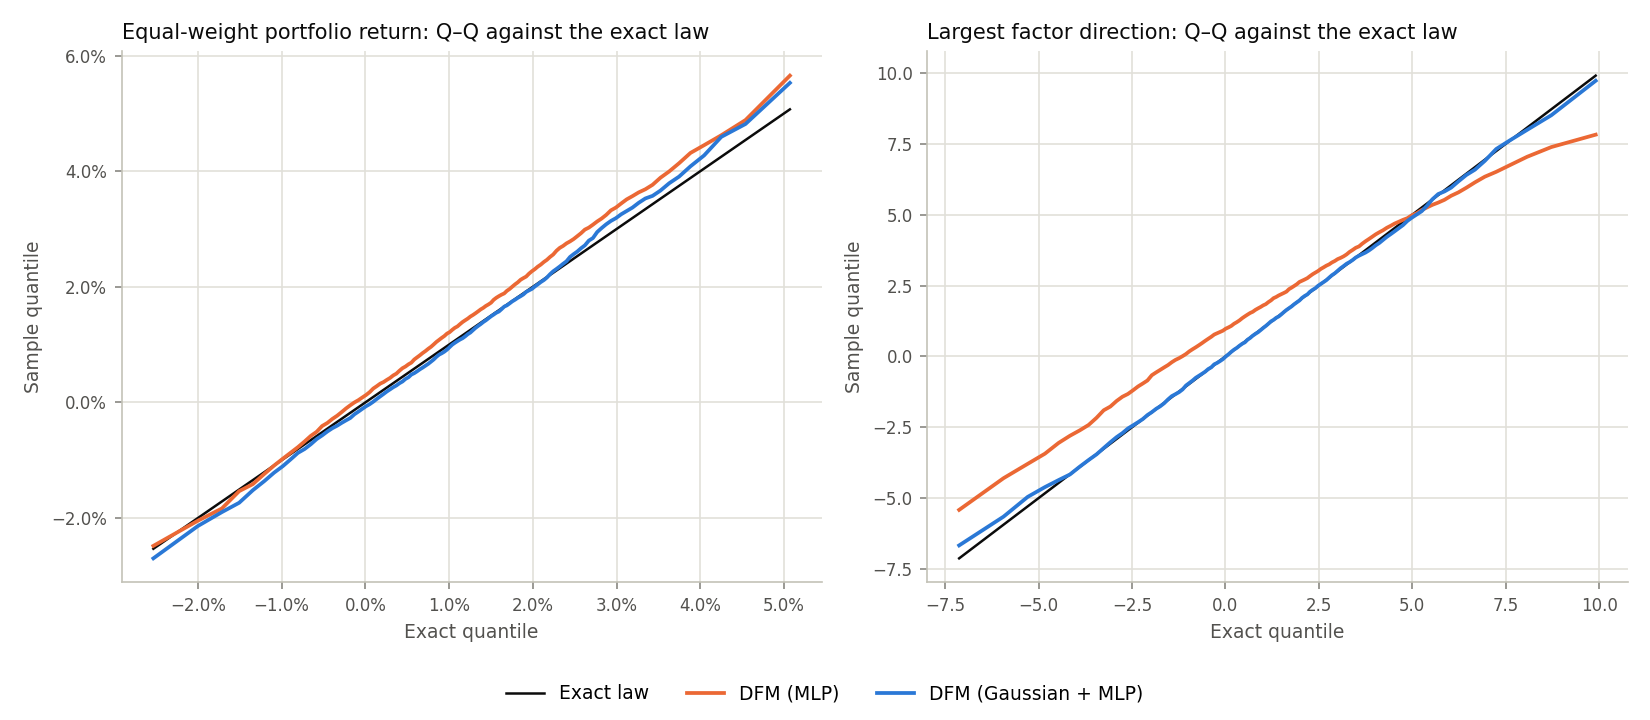

In [8]:
# Q–Q plots of both DFMs against the exact law: the portfolio and the largest factor direction.
generated_samples = {}
for network in DFM_NETWORKS:
    with np.load(OUTPUT / dfm_folder_name("gaussian", CONFIG.seeds[0], network) / "unconditional_samples.npz") as saved:
        generated_samples[network] = saved["generated"]
        truth_sample = saved["truth"]
dfm_figure = plot_dfm_distributions(generated_samples, population, OUTPUT / "dfm_distributions.png")

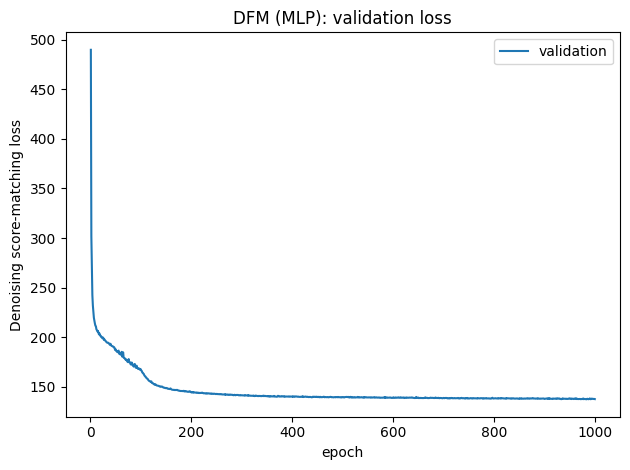

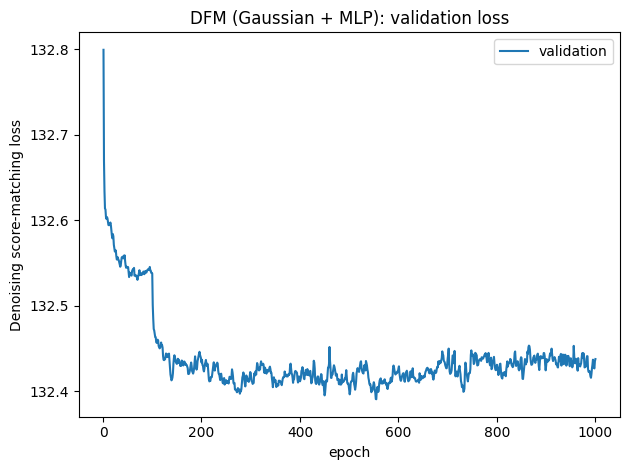

In [9]:
for network in DFM_NETWORKS:
    plot_dfm_validation(OUTPUT / dfm_folder_name("gaussian", CONFIG.seeds[0], network), DFM_LABELS[network])

### Metrics against the exact law

Two short tables summarize the two DFMs. The first puts the equal-weight portfolio's
mean, volatility and 5% and 1% quantiles next to their exact values, with the range
of variance ratios along the identifiable factor directions (target 1).

The second gives three distances, lower is better: the portfolio KS distance to the
exact CDF, the sliced W1 distance to an independent ground-truth sample (64 random
directions, sensitive to the joint law), and the relative error to the exact
covariance. KS and covariance errors thus use the analytic truth, while sliced W1
compares two samples. Each sits next to its noise level: the 95% quantile of the same
distance when the compared sample is itself exact, over 100 replicates of the same size.
A value at or below it cannot be told apart from sampling noise. All metrics remain in
`metrics.csv`.

In [10]:
dfm_values, dfm_distances = dfm_tables(generated_samples, truth_sample, population,
                                       verdict="gaussian_mlp", noise_seed=42010)
values_note, distances_note = table_notes(len(truth_sample))
dfm_values.to_csv(OUTPUT / "dfm_values.csv")
dfm_distances.to_csv(OUTPUT / "dfm_distances.csv")
conclusions = (
    f"Benchmark: seed {CONFIG.seeds[0]}, d={CONFIG.d}, k={CONFIG.k}, {CONFIG.n_train:,} training observations.\n\n"
    + values_note + "\n\n" + dfm_values.to_markdown() + "\n\n"
    + distances_note + "\n\n" + dfm_distances.to_markdown() + "\n"
)
(OUTPUT / "conclusions.md").write_text(conclusions)
display(Markdown(values_note), dfm_values, Markdown(distances_note), dfm_distances)

**Unconditional returns: values next to the exact law.**

,Exact,DFM (MLP),DFM (Gaussian + MLP)
Mean portfolio return,1.27%,1.49%,1.27%
Portfolio volatility,1.48%,1.60%,1.58%
5% quantile of the portfolio return,-1.16%,-1.16%,-1.28%
1% quantile of the portfolio return,-2.16%,-2.21%,-2.31%
Factor variances relative to the exact ones (min–max),1.00,0.66–0.84,0.92–1.12


**Unconditional returns: distances (lower is better).** Each source uses 3,000 rows. KS and covariance errors use the analytic truth; sliced W1 compares samples. The noise level is the 95% quantile of the same distance when the compared sample is itself exact: a value at or below it cannot be told apart from sampling noise.

,DFM (MLP),DFM (Gaussian + MLP),"Noise level (95%, n=3,000)",DFM (Gaussian + MLP) within noise?
Portfolio: KS distance to the exact law,0.068,0.030,0.026,no
Joint law: sliced W1 distance to the ground truth,0.039,0.019,0.014,no
Covariance: relative error to the exact covariance,0.307,0.100,0.078,no


## 3. Freeze the DFM and construct conditioning coordinates

[`FrozenDFMReference(model)`](reference.py) deep-copies the trained DFM (Gaussian + MLP) score,
freezes every parameter, and fixes its time settings. Input derivatives remain
available, so freezing the DFM does not prevent guidance differentiation.

Let $s=T-t$, $\Lambda_s=D_s^{-1}$, and

$$
\ell_t=\frac{\alpha_s}{\alpha_{t_0}}D_s\Lambda_{t_0}w,
\qquad
G_t=\begin{bmatrix}V^\top D_s\\\ell_t^\top\end{bmatrix},
\qquad
Y_t=G_tX_t=(Z_t,U_t).
$$

At $t=\tau$, $s=t_0$ and $D_{t_0}\Lambda_{t_0}=I$, hence
$\ell_\tau=w$ and $U_\tau=w^\top X_\tau$. This keeps the entire portfolio event,
including the residual return contribution. Earlier $U_t$ generally differs from
$w^\top X_t$.

## 4. Compare CDG-ML and Refined CDG-ML

The continuous-time target is the terminal-event probability of Guo et al. (2026),
written in the reduced coordinates:

$$
H(t,y)=P(U_\tau\le C\mid Y_t=y),\qquad
H(\tau,y)=\mathbf1\{u\le C\}.
$$

The notebook trains two H models on the **same frozen DFM and the same training,
validation, and test trajectories**. Here **CDG-ML** is the martingale-loss method of Guo et al. (2026):
it regresses the terminal event indicator on $(t,Y_t)$
along unguided paths of the frozen pretrained model with a squared loss, then
guides with $\nabla\log H_\phi$. We apply it to the reduced coordinates $Y_t$ rather
than the full state, without any of the five refinements: unstandardized coordinates, normalized time only,
binary terminal labels at every preterminal time, ordinary interval weights
$\omega_j$, and MSE (Brier) loss. CDG-ML uses every stored time per trajectory.
In standard mode, both variants use the same hidden widths, learning rate and training budget:
40,000 training trajectories for 50 epochs, validated every 157 optimizer steps (configuration
table above). The five refinements and their assumptions are detailed in
[METHODS.md](METHODS.md). Each variant selects its checkpoint by its own validation
objective, so the two validation losses (MSE and BCE) are not comparable.

Guo et al. (2026) note that an accurate $H_\phi$ need not give an accurate
$\nabla\log H_\phi$, and propose a covariation-based loss (CDG-MCL) that learns
$\nabla H$ separately. The refinements below address the same problem
differently; CDG-MCL is not implemented here.

**Refined CDG-ML** adds the following five refinements:

1. **Standardization of the reduced coordinates.** We standardize each reduced coordinate using time-dependent means and standard deviations estimated from the training trajectories. This keeps coordinates with large magnitudes from dominating the network inputs and limits saturation of the Tanh activations. Standardization remains inside the network’s computational graph, preserving the chain rule used for guidance.

2. **An additional temporal input.** Alongside normalized time, we provide the log remaining time,
   $$
   \log\left(\frac{\max(\tau-t,\Delta t)}{\tau}\right),
   $$
   bringing the input dimension to $k+3$. This input gives the network resolution near the terminal time, where the event probability becomes increasingly sharp. The floor $\Delta t$ keeps the logarithm finite.

3. **An exact probability target at the last preterminal time.** At earlier times, the target remains the binary terminal label. At the last preterminal time, we replace this label with the exact event probability for the frozen DFM’s final Euler step. This integrates out the final Gaussian noise instead of relying on a single realized outcome. The binary label is already an unbiased target; the exact probability has the same mean and less sampling noise.

4. **Greater emphasis on late times.** We increase the loss weights near the terminal time, particularly at the last preterminal step. As less time remains for future noise to influence the outcome, the event probability changes more sharply around the threshold, so more of the training weight goes there. The weights depend only on time, so the population minimizer is still the conditional probability.

5. **Binary cross-entropy instead of mean squared error.** We use BCE, implemented directly from logits for numerical stability. For a sigmoid output, its gradient with respect to the logit is $H_\phi-p$, whereas MSE introduces an additional factor proportional to $H_\phi(1-H_\phi)$. BCE therefore avoids this extra attenuation when predictions are confident but incorrect.

## 5. Generate conditional returns

The conditional initial density for exact H is proportional to
$H(0,G_0x)\varphi_d(x)$. Therefore
[`sample_conditional_initial`](guided_sampling.py) proposes $x\sim N(0,I_d)$
and accepts with probability $H_\phi(0,G_0x)$. This samples the normalized *learned* H tilt; it
equals the desired initial law only for exact H. The guided samplers of Guo et al. (2026) start from the
unconditional noise law instead.

For exact continuous-time H, the ambient Doob correction is

$$
\nabla_x\log H(t,G_tx)=G_t^\top\nabla_y\log H(t,G_tx),
$$

and the guided SDE (Guo et al., 2026) is

$$
dX_t=\left[\tfrac12X_t+s_\theta(X_t,T-t)
+G_t^\top\nabla_y\log H(t,G_tX_t)\right]dt+dW_t.
$$

The exact conditioning formula describes a continuous diffusion. A learned H and
finite-step Euler integration do not guarantee exact samples from the discrete
reference sampler conditioned on its terminal event. Independent DFM rejection
therefore remains the reference for the conditioning step.

### Exact final step

The Doob correction only shifts the mean of each Gaussian Euler step. At the last
step this cannot reproduce the conditioned transition, whatever the accuracy of H.
With $\mu(x)=x+\Delta t\,b(t_{J-1},x)$ and $b(t,x)=\tfrac12x+s_\theta(x,T-t)$, the unguided
last step is $X_J\mid X_{J-1}=x\sim N(\mu(x),\,\Delta t\,I_d)$. Because the event depends
only on $X_J$, the finite-grid conditioned transition is this Gaussian restricted
to the half-space:

$$
p(x_J\mid x,E)\propto\varphi_d\!\big((x_J-\mu(x))/\sqrt{\Delta t}\big)\,
\mathbf 1\{w^\top x_J\le C\},\qquad
a(x)=\frac{C-w^\top\mu(x)}{\sqrt{\Delta t}\,\lVert w\rVert}.
$$

Every draw satisfies the event, up to numerical
rounding, and no draw is discarded. No H enters this step. Here
$\sqrt{\Delta t}\,\lVert w\rVert\simeq0.0063$ in the standard experiment.
The Chen population has a portfolio standard deviation of approximately $0.0148$,
so this final-step noise scale is substantial relative to the clean portfolio
variation. The exact event thresholds are displayed in section 1.

The conditioned path law factorizes as
$P(x_{0:J}\mid E)=P(x_{0:J-1}\mid E)\,P(x_J\mid x_{J-1},E)$: H-guidance approximates the
first factor over steps $0,\dots,J-2$ and the second is drawn exactly. The step
costs less than one guided Euler step.

We cannot repeat this truncation at every earlier step to obtain the same conditional
law. An earlier transition must be weighted by the probability of reaching the event
after **all remaining steps**, rather than by $\mathbf1\{w^\top x_{j+1}\le C\}$.
That future-event probability is H; truncating every intermediate state would impose
a different path constraint. H guidance prepares the preterminal distribution,
while exact truncation handles the final innovation. Without guidance, paths can
arrive far above $C$, and the exact last step then concentrates them just below the
threshold. [METHODS.md](METHODS.md), section 5, gives the event probability and the
sampling formula of this exact final step.

In the benchmark, both CDG-ML and Refined CDG-ML use
`sample_h_guided(..., final_step="exact")`, so their comparison isolates H training.
Both use the same guided seed and H-tilted starts drawn from their own H. A third
source uses unguided paths from $N(0,I_d)$ followed by the same exact final step,
isolating the need for H guidance. Every sampled row is kept: no draw is filtered.


## 6. Evaluate the five sources of conditional returns

| Source | How it is produced |
| --- | --- |
| Conditional ground truth | `population.sample(N, rng, c=C)`: the exact truncated Gaussian law of the population |
| DFM rejection sampling | [`sample_dfm_rejection`](synthetic_benchmark/conditional.py): unguided draws of the frozen DFM on the same grid, keeping $w^\top X_\tau\le C$ |
| CDG-ML + exact final step | H without refinements, guided Euler steps, exact last step |
| Refined CDG-ML + exact final step | H with the five refinements, guided Euler steps, exact last step |
| No guidance + exact final step | Unguided paths from $N(0,I_d)$, exact last step |

DFM rejection is the reference for the numerical DFM's conditional law, which may
differ from the population conditional law. The comparisons separate three questions; the last row gives their Monte Carlo levels:

| Comparison | What it assesses |
| --- | --- |
| DFM rejection vs ground truth | Error in the learned numerical reference law |
| Guided vs DFM rejection | Error introduced by the learned conditioning and guided integration |
| Guided vs ground truth | Combined conditional-generation error |
| Independent truth vs truth, rejection vs rejection | Monte Carlo levels at the same sample sizes |

[`run_conditional_benchmark`](synthetic_benchmark/conditional.py) draws two independent
DFM rejection streams and two independent ground-truth samples, with seeds distinct from
every training and sampling stream. `conditional_comparisons` in
[reporting.py](synthetic_benchmark/reporting.py) compares fixed seeded subsets of equal
size, so each Monte Carlo level has the sample size of the comparison it describes. These
sample-to-sample distances, saved in `comparisons.csv`, are the portfolio KS and W1 and
the sliced W1 over 64 random unit directions, which is sensitive to the joint structure.
Against population truth, `moments.csv` adds the analytic portfolio KS, which compares a
source with the exact conditional CDF, and the mean and covariance errors to the exact
conditional moments.

The function shows the Refined CDG-ML validation curve and a table of H diagnostics
for both H models on the same held-out test paths. It then shows one figure and two
tables per event. These show DFM rejection and Refined CDG-ML only, against the exact
conditional law. All five sources are saved: their samples in `conditional_samples.npz`
and their distances and moments in `comparisons.csv`, `moments.csv` and `summary.csv`.

The figure shows distributions only: the portfolio CDF given the event, the portfolio
Q–Q plot, and the Q–Q plot along the largest factor direction $Bu_1$, with $u_1$ the
leading eigenvector of the factor covariance. The last one checks the joint law beyond
the portfolio. Its exact quantiles given the event integrate numerically over the
truncated portfolio law.

The first table puts the expected shortfall $E[P\mid P\le C]$ and the volatility given
the event next to their exact values, with the share of rows in the event (with a
$10^{-5}$ rounding tolerance). The second gives the portfolio KS distance to the exact
conditional CDF, the sliced W1 distance to the ground-truth sample, and the relative
error to the exact conditional covariance: KS and covariance errors use the analytic
truth, while sliced W1 compares samples. Every source uses as many rows as the DFM
rejection sample, so one noise level applies: the 95% quantile of the same distance
when the compared sample is itself exact, over 100 replicates of that size. The last
column says whether Refined CDG-ML is at or below it.
Standard mode uses 3,000 rows per guided, unguided, or truth source and 1,000 accepted
rows per rejection stream.

The gradient diagnostics use only final-preterminal test states whose exact final-step
event probability lies in $(0.01,0.99)$. Their count, `Gradient states (n)`, is reported
with the cosine and relative RMSE, since a high cosine on a small subset does not
establish an accurate gradient magnitude. The probability diagnostics use the full held-out test set.


In [11]:
from synthetic_benchmark.conditional import run_conditional_benchmark
from synthetic_benchmark.configuration import rejection_assessment

# Guidance targets the frozen DFM (Gaussian + MLP).
GAUSSIAN_MLP_CONFIG = replace(CONFIG, dfm_network="gaussian_mlp")
# The figure and the two tables show these sources against the exact law; the CSV files keep all five.
PLOT_SOURCES = ("truth", "rejection", "refined_exact")
# Both H models: 40k trajectories, 50 epochs, validation every 157 optimizer steps.
H_RECIPE = dict(
    plot_sources=PLOT_SOURCES,
    n_train=2_048 if CONFIG.mode == "smoke" else 40_000,
    n_validation=1_024 if CONFIG.mode == "smoke" else 2_000,
    n_test=1_024 if CONFIG.mode == "smoke" else 2_000,
    epochs=10 if CONFIG.mode == "smoke" else 50,
    validation_interval_steps=157,
    widths=(64, 64),
    initialization_seed=2027,
    lr=1e-3,
    batch_size=64,
    path_batch_size=256,
    train_seeds={"train": 32001, "validation": 32002, "test": 32003, "shuffle": 32004},
    n_samples=CONFIG.n_eval,
    sample_batch_size=256,
    guided_seed=42001,
    truth_seed=42002,
    unguided_seed=42008,
)
# Accepted rows per DFM rejection stream; a stream may draw up to 4 times the expected proposals.
REJECTION_ROWS = 128 if CONFIG.mode == "smoke" else 1_000
ASSESSMENT = dict(
    rejection_batch_size=2_048,
    rejection_seed=42003, rejection_reference_seed=42004, truth_reference_seed=42005,
    projection_seed=42006, matching_seed=42007, projections=64, noise_seed=42009,
)
print("Figure and tables: DFM rejection and Refined CDG-ML against the exact law. "
      "Saved CSV files: all five sources.")

Figure and tables: DFM rejection and Refined CDG-ML against the exact law. Saved CSV files: all five sources.


Assets: 500; factors: 8; event probability 5%; frozen DFM (Gaussian + MLP), epoch 555


Event: equal-weight portfolio return <= -0.011577


Generating 40,000 train trajectories...


  Terminal event: 2,533/40,000 (6.33%)


Generating 2,000 validation trajectories...


  Terminal event: 126/2,000 (6.30%)


... (22 outputs left out)

DFM rejection stream 'rejection' (cap 80,000 proposals)...


  complete: 1,000/1,000 rows from 16,384 proposals in 114s


DFM rejection stream 'rejection_reference' (cap 80,000 proposals)...


  complete: 1,000/1,000 rows from 16,384 proposals in 114s


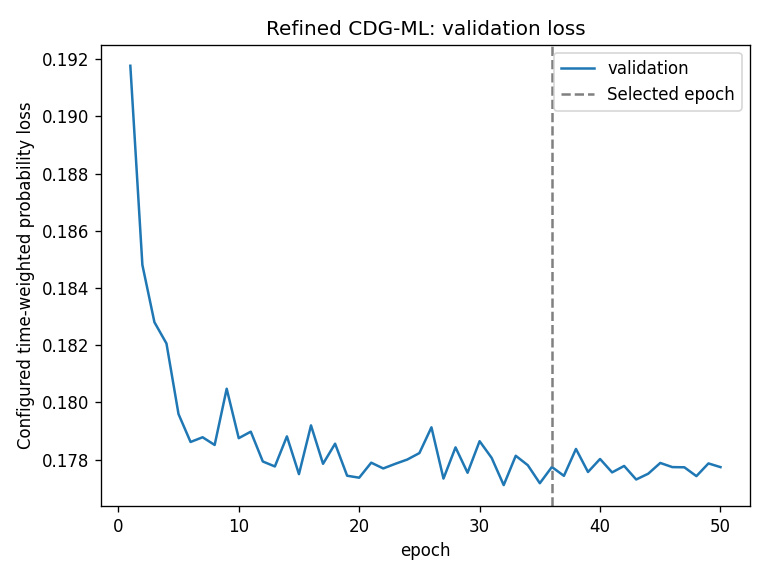

,Refined CDG-ML,CDG-ML
Held-out Brier loss,0.0614,0.0620
Constant-probability Brier loss,0.0651,0.0651
First-layer Tanh saturation,0.2019,0.8464
Last-step probability RMSE,0.0160,0.1560
Last-step gradient relative RMSE,0.1693,0.9759
Last-step gradient cosine,0.9996,0.3243
Gradient states (n),532,532
Selected epoch,36,47
Selected optimizer step,"21,980","29,202"


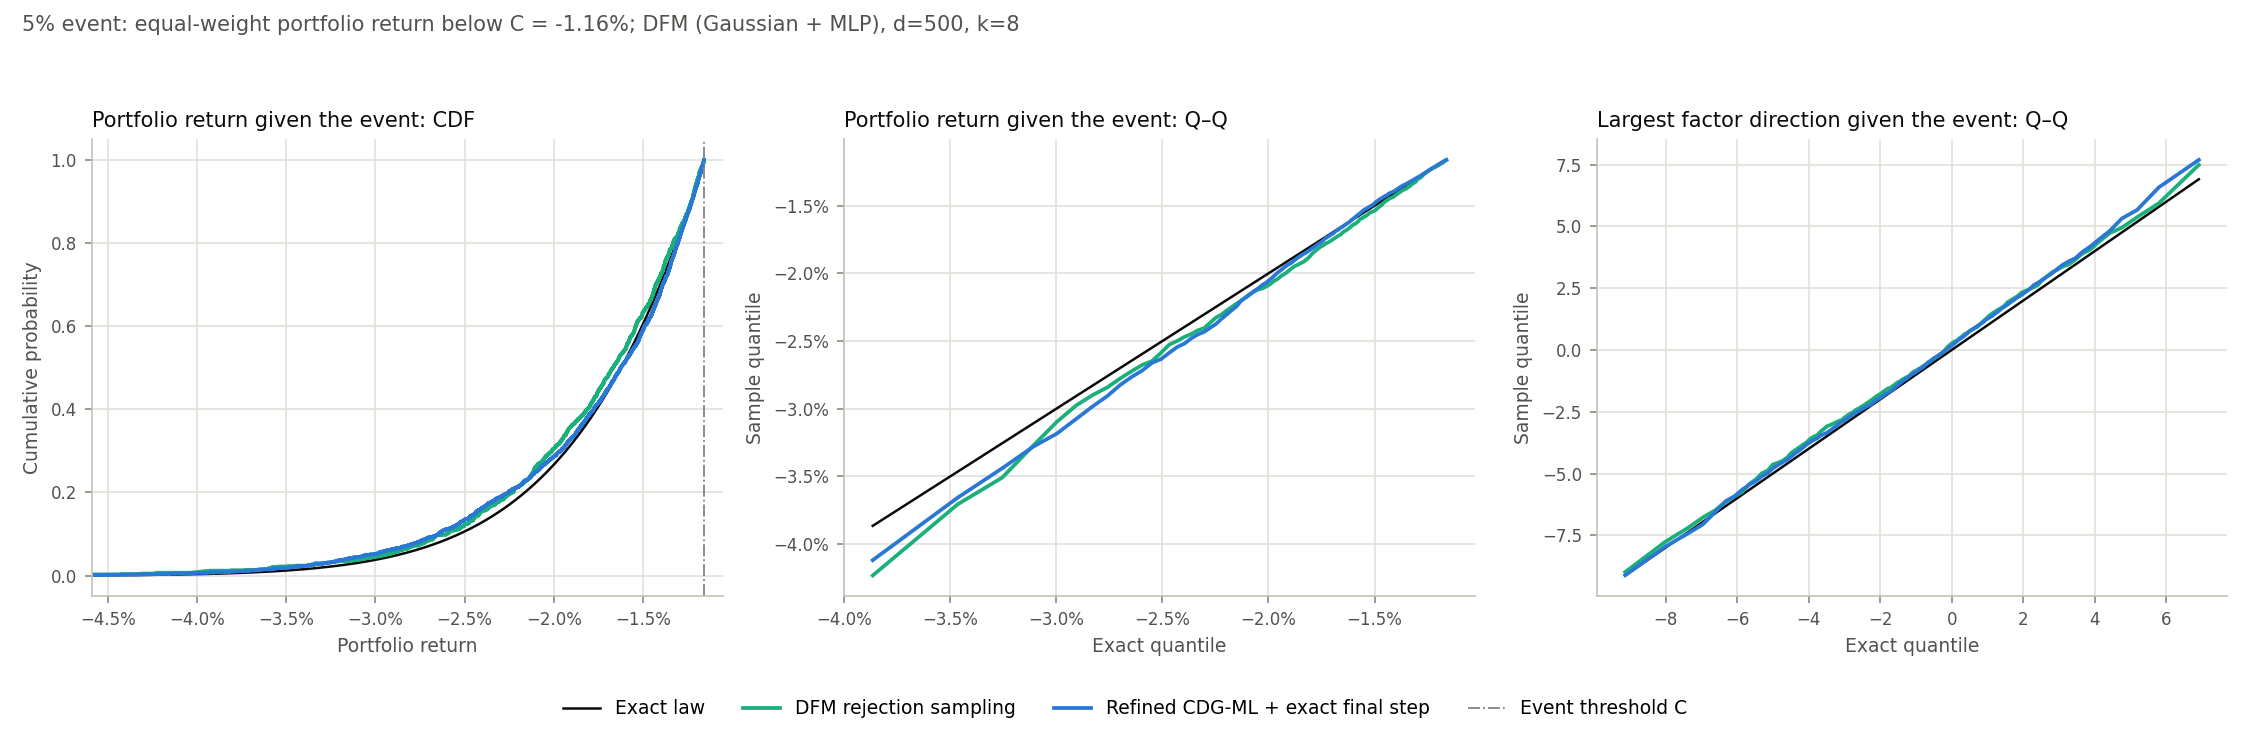

**5% event: values next to the exact law.**

,Exact,DFM rejection,Refined CDG-ML
Expected shortfall: mean return given the event,-1.77%,-1.83%,-1.81%
Volatility given the event,0.55%,0.60%,0.61%
Rows in the event,100.0%,100.0%,100.0%
Rows generated,—,"1,000","3,000"


**5% event: distances (lower is better).** Each source uses 1,000 rows. KS and covariance errors use the analytic truth; sliced W1 compares samples. The noise level is the 95% quantile of the same distance when the compared sample is itself exact: a value at or below it cannot be told apart from sampling noise.

,DFM rejection,Refined CDG-ML,"Noise level (95%, n=1,000)",Refined CDG-ML within noise?
Portfolio: KS distance to the exact law,0.046,0.043,0.045,yes
Joint law: sliced W1 distance to the ground truth,0.029,0.029,0.022,no
Covariance: relative error to the exact covariance,0.155,0.206,0.134,no


Conditional benchmark saved to: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T181844904153Z/conditional_tail0.05


In [12]:
conditional_5 = run_conditional_benchmark(
    GAUSSIAN_MLP_CONFIG, OUTPUT, tail=0.05, **H_RECIPE,
    assessment_settings=rejection_assessment(0.05, REJECTION_ROWS, **ASSESSMENT),
)

### The 1% event

Assets: 500; factors: 8; event probability 1%; frozen DFM (Gaussian + MLP), epoch 555


Event: equal-weight portfolio return <= -0.021632


Generating 40,000 train trajectories...


  Terminal event: 609/40,000 (1.52%)


Generating 2,000 validation trajectories...


  Terminal event: 36/2,000 (1.80%)


... (22 outputs left out)

DFM rejection stream 'rejection' (cap 400,000 proposals)...


  complete: 1,000/1,000 rows from 61,440 proposals in 446s


DFM rejection stream 'rejection_reference' (cap 400,000 proposals)...


  complete: 1,000/1,000 rows from 65,536 proposals in 495s


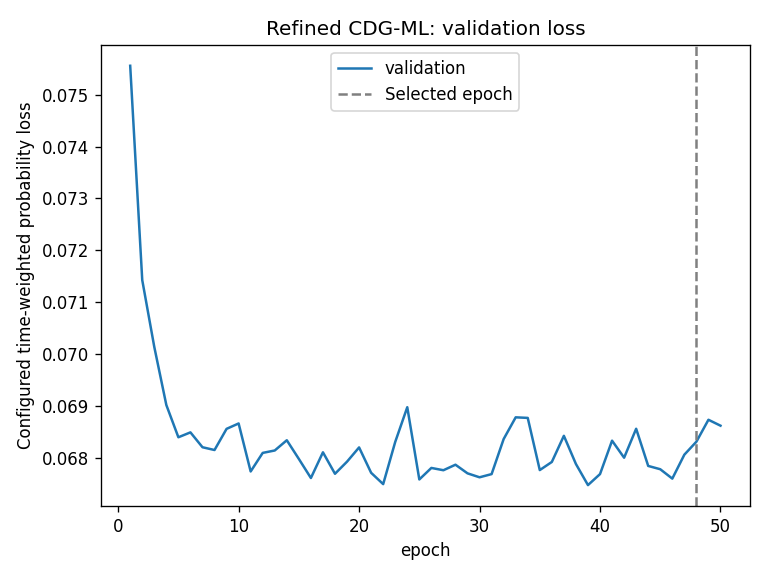

,Refined CDG-ML,CDG-ML
Held-out Brier loss,0.0169,0.0173
Constant-probability Brier loss,0.0177,0.0177
First-layer Tanh saturation,0.2402,0.8915
Last-step probability RMSE,0.0130,0.0931
Last-step gradient relative RMSE,0.1840,1.0273
Last-step gradient cosine,0.9991,0.1192
Gradient states (n),196,196
Selected epoch,48,50
Selected optimizer step,"29,673","30,929"


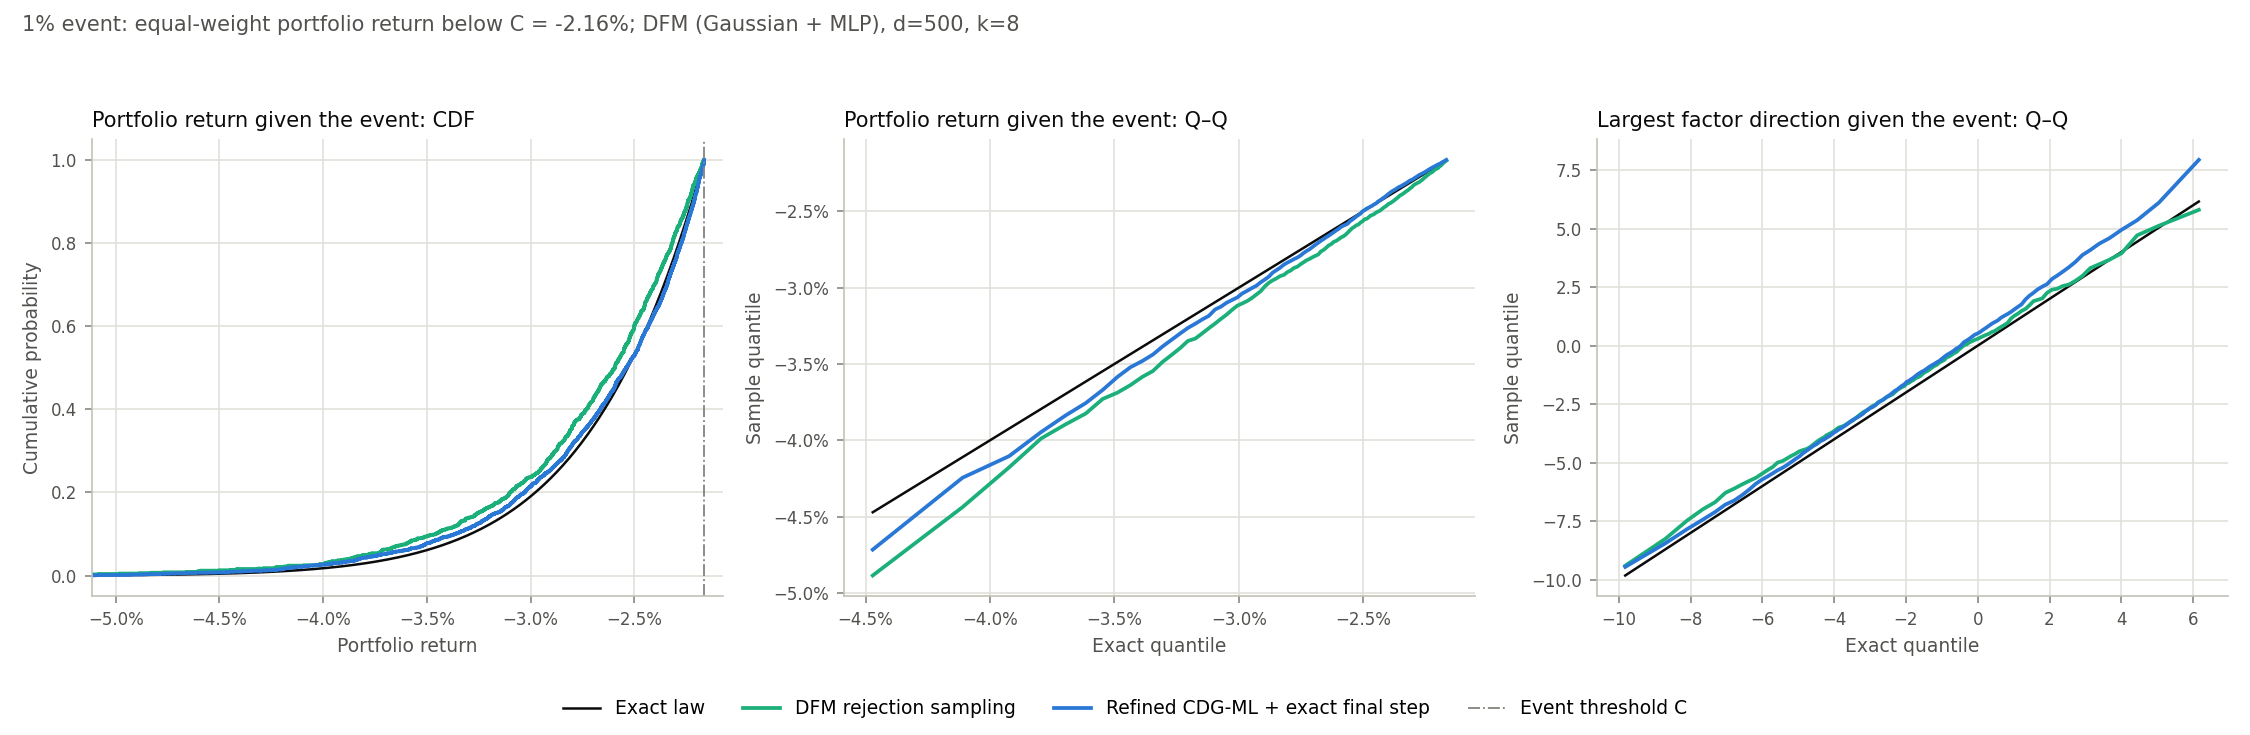

**1% event: values next to the exact law.**

,Exact,DFM rejection,Refined CDG-ML
Expected shortfall: mean return given the event,-2.66%,-2.75%,-2.69%
Volatility given the event,0.46%,0.53%,0.50%
Rows in the event,100.0%,100.0%,100.0%
Rows generated,—,"1,000","3,000"


**1% event: distances (lower is better).** Each source uses 1,000 rows. KS and covariance errors use the analytic truth; sliced W1 compares samples. The noise level is the 95% quantile of the same distance when the compared sample is itself exact: a value at or below it cannot be told apart from sampling noise.

,DFM rejection,Refined CDG-ML,"Noise level (95%, n=1,000)",Refined CDG-ML within noise?
Portfolio: KS distance to the exact law,0.073,0.033,0.045,yes
Joint law: sliced W1 distance to the ground truth,0.033,0.041,0.022,no
Covariance: relative error to the exact covariance,0.150,0.280,0.134,no


Conditional benchmark saved to: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T181844904153Z/conditional_tail0.01


In [14]:
conditional_1 = run_conditional_benchmark(
    GAUSSIAN_MLP_CONFIG, OUTPUT, tail=0.01, **H_RECIPE,
    assessment_settings=rejection_assessment(0.01, REJECTION_ROWS, **ASSESSMENT),
)

In [16]:
print("Samples, tables and figures saved under:", OUTPUT)

Samples, tables and figures saved under: /Users/yann/Documents/GitHub/Master-Thesis/artifacts/synthetic_unconditional_benchmark/standard_20261108T181844904153Z


## Reading the current results

The tables and figures above report the current execution on the Chen Gaussian
population: the two unconditional DFMs, then DFM rejection and Refined CDG-ML at the
5% and 1% events, each against the exact law. All five conditional sources are saved
in the run's artifact folder, printed by the cell above. Check its saved configuration
and completion status before interpreting a run; conditional results from an earlier
checkpoint are not results of the current execution.

Read the figures first: a curve on the exact law (the diagonal of a Q–Q plot) means
the source reproduces that distribution. Then read the tables above: the values show
how far the expected shortfall and volatility are from the exact ones, and the last
column of each distance table says whether each distance can be explained by sampling
noise. Agreement on one distance does not establish agreement on the others: a
portfolio KS within noise can coexist with a sliced W1 or a covariance error above it.
An exact final step guarantees the event up to rounding but not the correct conditional
distribution; the no-guidance results in `summary.csv` show the difference.

### CDG-ML against Refined CDG-ML

The table below compares both H models with DFM rejection, their common reference, so
it separates conditioning error from the DFM's own error. It is read from the saved
`comparisons.csv` of each event and stored as `conditioning_error.csv` in the run folder.

In [17]:
from synthetic_benchmark.reporting import conditioning_error_table, readable_conditioning_error

# Read back the matched comparisons saved for both events: nothing is trained or sampled again.
saved_comparisons = {tail: pd.read_csv(OUTPUT / f"conditional_tail{tail}" / "comparisons.csv")
                     for tail in (0.05, 0.01)}
conditioning_error = conditioning_error_table(saved_comparisons)
conditioning_error.to_csv(OUTPUT / "conditioning_error.csv")
conditioning_note, conditioning_display = readable_conditioning_error(conditioning_error)
display(Markdown(conditioning_note), conditioning_display)

**Conditioning error: distances to DFM rejection (lower is better).** Both H models use the exact final step, and each distance compares 1,000 matched rows with the DFM rejection sample. The rejection-vs-rejection reference is the same distance between two independent DFM rejection streams of that size: one Monte Carlo draw, which describes sampling variation; it is not a 95% noise level.

CDG-ML Refined CDG-ML  \
Event    Metric                                          
5% event Portfolio KS distance    0.232          0.052   
         Portfolio W1 distance  0.00211       0.000448   
         Sliced W1 distance      0.0356         0.0212   
1% event Portfolio KS distance    0.376          0.081   
         Portfolio W1 distance  0.00327       0.000631   
         Sliced W1 distance      0.0421         0.0289   

                               Rejection-vs-rejection reference  
Event    Metric                                                  
5% event Portfolio KS distance                            0.059  
         Portfolio W1 distance                         0.000325  
         Sliced W1 distance                              0.0189  
1% event Portfolio KS distance                            0.048  
         Portfolio W1 distance                         0.000294  
         Sliced W1 distance                              0.0199

Against DFM rejection, Refined CDG-ML improves on CDG-ML for every distance at both
events, most on the portfolio: its KS and W1 distances are 4.5 to 5.2 times smaller and
its sliced W1 distance is 31–41% smaller. Some conditioning error remains and grows at
the rarer event: at 5%, its portfolio KS distance is below the rejection-vs-rejection
reference while both W1 distances remain above it; at 1%, all three distances increase
and exceed the reference, the portfolio W1 distance about twofold. Against population
truth, the portfolio KS distance of Refined CDG-ML is within the reported noise level at
both events, while its sliced W1 and covariance errors remain above it.

**Limitations.**
* The standard configuration uses one DFM seed, one H initialization and one fixed
  synthetic population, so variability across seeds is not estimated.
* The Gaussian + MLP network is favored by the Gaussian population; this experiment
  tests conditioning on synthetic Gaussian returns. Compare the untrained Gaussian
  initialization separately before attributing an improvement to neural training.
* The sampling grid, stopping time, observation counts and training budgets were not
  tuned for this population, whose small scales and near-zero residual variances can
  affect accuracy; the unconditional and conditional errors above show their effect.
* The five refinements are applied together, so their individual effects are not isolated.
* Runtimes are saved in each event's `run.json` but not compared here; they depend on
  the machine, the event frequency and the number of scenarios.

[METHODS.md](METHODS.md) gives the formulas and settings behind these comparisons.
